# 10. Boiling and condensation

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 7 and 9

When a liquid boils or a vapour condenses, the latent heat is released or absorbed at a
nearly fixed temperature, and heat transfer coefficients reach tens of thousands of
W/(m² K), a hundred times those of Chapter 9. Every steam power plant rejects most of its
heat in a condenser, and every boiler, kettle and reactor core relies on boiling. Boiling
also has a limit, the *critical heat flux*, beyond which the surface is covered by vapour
and its temperature jumps by hundreds of kelvin.

Two problems frame the chapter. A combined heat and power plant, like those that heat
Astana, condenses the exhaust steam of its turbines at 40 °C on banks of horizontal tubes
cooled by water: how much heat does a metre of tube take up, and which resistance
controls it? And an electric immersion heater boils water at atmospheric pressure: how
far is it from the critical heat flux, and what happens if it is exceeded? Nusselt's 1916
film theory answers the first. A short exact analysis, checked by collocation and by
marching down the plate, shows how much the cooling of the condensate film adds to it.
Correlations built on hydrodynamic theory and experiments answer the second.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import quad
from scipy.optimize import brentq

try:
    from engtransport import convection_int, phase_change, properties, reference
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import convection_int, phase_change, properties, reference
from engtransport.constants import SIGMA_SB
from engtransport.plotting import panel_label, use_style

use_style()
g = 9.80665                  # m/s2

## 10.1 Film condensation on a vertical plate

Saturated vapour at $T_{sat}$ meets a vertical wall at $T_w < T_{sat}$. It condenses on the
wall, and the condensate runs down as a thin film whose thickness $\delta(x)$ grows with
the distance $x$ from the top. Nusselt (1916) took the film to be laminar and so thin that
inertia is negligible: gravity on the liquid, less the buoyancy of the surrounding vapour,
balances viscous shear. With no shear from the still vapour at the free surface, the
velocity profile and the mass flow per unit width are

$$
u(y) = \frac{g(\rho_l - \rho_v)}{\mu_l}\left(\delta y - \frac{y^2}{2}\right) , \qquad
\Gamma = \int_0^\delta \rho_l u\,dy = \frac{g\rho_l(\rho_l - \rho_v)\,\delta^3}{3\mu_l} .
\tag{10.1}
$$

Heat is conducted across the film, from the interface at $T_{sat}$ to the wall. If the
temperature profile is linear, the heat flux $k_l\Delta T/\delta$, with
$\Delta T = T_{sat} - T_w$, removes the latent heat of the vapour that condenses on a
length $dx$: $k_l\Delta T\,dx/\delta = h_{fg}\,d\Gamma$. Substituting $\Gamma(\delta)$ and
integrating from $\delta = 0$ at the top gives

$$
\delta(x) = \left[\frac{4\mu_l k_l \Delta T\,x}{g\rho_l(\rho_l - \rho_v)h_{fg}}\right]^{1/4} ,
\tag{10.2}
$$

and the coefficient $h_x = k_l/\delta$ falls as $x^{-1/4}$. Over a height $L$ the mean
coefficient is $4/3$ of the local one at the bottom:

$$
\bar h_L = 0.943\left[\frac{g\rho_l(\rho_l - \rho_v)h_{fg}k_l^3}{\mu_l\,\Delta T\,L}\right]^{1/4} .
\tag{10.3}
$$

The film thickens downwards as it collects condensate, so the top of the wall does most
of the work, and a larger temperature difference *lowers* $h$, because it thickens the
film. The film becomes wavy at modest film Reynolds numbers, $4\Gamma/\mu_l$, which raises
$h$ somewhat, and turbulent at large ones; Eq. (10.3) is the laminar result.

## 10.2 The subcooling of the film

Nusselt's linear profile ignores one effect: the liquid in the film is colder than
$T_{sat}$, so the wall removes not only the latent heat but also the sensible heat given up
as the condensate cools. Counting the enthalpy carried by the film with the linear profile
adds $(3/8)c_{p}\Delta T$ to $h_{fg}$. But the convection of heat along the film also
bends the temperature profile, and that changes the heat flux at the wall.

The full energy equation of the film, $u\,\partial T/\partial x + v\,\partial T/\partial y
= \alpha_l\,\partial^2 T/\partial y^2$, with Nusselt's velocity (10.1), can be solved
exactly. With $\eta = y/\delta$ and $\theta = (T - T_w)/\Delta T$, a film of thickness
$\delta \propto x^{1/4}$ has self-similar profiles that satisfy

$$
\theta'' + \lambda f(\eta)\,\theta' = 0 , \qquad f = \frac{\eta^2}{2} - \frac{\eta^3}{6} ,
\qquad \theta(0) = 0 , \quad \theta(1) = 1 , \quad \theta'(1) = \frac{\lambda}{3\,\mathrm{Ja}} ,
\tag{10.4}
$$

where $f$ is the dimensionless stream function of Eq. (10.1), the last condition is the
latent-heat balance at the interface, and $\mathrm{Ja} = c_{p}\Delta T/h_{fg}$ is the
*Jakob number*, the ratio of sensible to latent heat. The equation integrates once:
$\theta' = c\,e^{-\lambda F}$ with $F = \eta^3/6 - \eta^4/24$ and
$1/c = \int_0^1 e^{-\lambda F}d\eta$, and the eigenvalue $\lambda$ follows from
$c\,e^{-\lambda/8} = \lambda/(3\,\mathrm{Ja})$. The result has Nusselt's form, Eq. (10.3),
with $h_{fg}$ replaced by

$$
\frac{h_{fg}'}{h_{fg}} = c^4\,\frac{3\,\mathrm{Ja}}{\lambda}
= 1 + \frac{27}{40}\mathrm{Ja} + \dots \qquad (\mathrm{Ja} \to 0) .
\tag{10.5}
$$

The small-Ja expansion follows from one step of perturbation theory in $\lambda$.
Rohsenow (1956) found the coefficient 0.68 from a similar analysis, and $h_{fg} +
0.68\,c_p\Delta T$ is the form used in practice; the exact coefficient is $27/40 =
0.675$. `phase_change.film_condensation_subcooling` solves Eqs. (10.4) by Gauss–Legendre
quadrature and bisection.

In [2]:
for Ja in (0.01, 0.1, 0.5, 1.0, 2.0):
    r = phase_change.film_condensation_subcooling(Ja)
    print(f"Ja = {Ja:5.2f}: lambda = {r['lam']:.5f}, h_fg'/h_fg = {r['ratio']:.5f}  "
          f"(Rohsenow 1 + 0.68 Ja = {1 + 0.68 * Ja:.4f}; linear profile 1 + 3/8 Ja = {1 + 0.375 * Ja:.4f})")
sat100 = properties.saturated_water(373.15)
for T_wall in (90.0, 50.0):
    Ja = properties.water_properties(273.15 + 0.5 * (100 + T_wall))["cp"] * (100 - T_wall) / sat100["h_fg"]
    print(f"steam at 100 C on a wall at {T_wall:.0f} C: Ja = {Ja:.3f}, h raised by "
          f"{100 * (phase_change.film_condensation_subcooling(Ja)['ratio'] ** 0.25 - 1):.1f} %")

Ja =  0.01: lambda = 0.02992, h_fg'/h_fg = 1.00675  (Rohsenow 1 + 0.68 Ja = 1.0068; linear profile 1 + 3/8 Ja = 1.0037)
Ja =  0.10: lambda = 0.29206, h_fg'/h_fg = 1.06774  (Rohsenow 1 + 0.68 Ja = 1.0680; linear profile 1 + 3/8 Ja = 1.0375)
Ja =  0.50: lambda = 1.32672, h_fg'/h_fg = 1.34326  (Rohsenow 1 + 0.68 Ja = 1.3400; linear profile 1 + 3/8 Ja = 1.1875)
Ja =  1.00: lambda = 2.39895, h_fg'/h_fg = 1.69679  (Rohsenow 1 + 0.68 Ja = 1.6800; linear profile 1 + 3/8 Ja = 1.3750)
Ja =  2.00: lambda = 4.08365, h_fg'/h_fg = 2.42910  (Rohsenow 1 + 0.68 Ja = 2.3600; linear profile 1 + 3/8 Ja = 1.7500)
steam at 100 C on a wall at 90 C: Ja = 0.019, h raised by 0.3 %
steam at 100 C on a wall at 50 C: Ja = 0.093, h raised by 1.5 %


For steam the correction is small: even at $\mathrm{Ja} = 0.09$, a wall 50 K below the
saturation temperature, $h$ rises by only 1.5 %. Water's latent heat is large. For
refrigerants and organic vapours, whose latent heats are a tenth as large, Ja reaches
0.5 or more, and the correction is worth tens of per cent. Rohsenow's linear form stays
within 1 % of the exact ratio up to $\mathrm{Ja} = 1$.

## 10.3 Horizontal tubes and the condenser

On a horizontal tube of diameter $D$ the film starts at the top, runs around both sides
and drips off the bottom. The same balance, with gravity resolved along the surface,
gives a film whose thickness at the angle $\phi$ from the top is proportional to
$\left(\int_0^\phi \sin^{1/3}\phi'\,d\phi'\right)^{1/4}/\sin^{1/3}\phi$, and a mean
coefficient

$$
\bar h_D = 0.728\left[\frac{g\rho_l(\rho_l - \rho_v)h_{fg}'k_l^3}{\mu_l\,\Delta T\,D}\right]^{1/4} ,
\qquad 0.728 = \frac{4\,S^{3/4}}{3\pi\,2^{1/4}} , \quad
S = \int_0^\pi \sin^{1/3}\phi\,d\phi = \frac{\sqrt{\pi}\,\Gamma(2/3)}{\Gamma(7/6)} .
\tag{10.6}
$$

The length in Eq. (10.6) is the diameter, not the height of a wall, so a tube of 25 mm
has a coefficient $(0.728/0.943)(1/0.025)^{1/4} = 1.9$ times that of a vertical tube 1 m
long: condensers use horizontal tubes. In a bank of $N$ tubes one above another, the
condensate from each tube falls on the next, and Nusselt's analysis gives a mean
coefficient $N^{-1/4}$ times that of a single tube; splashing makes real banks somewhat
better than this.

The condenser of a steam turbine at a combined heat and power plant condenses exhaust
steam at 40 °C, a pressure of 7.4 kPa. The tubes are stainless steel, 25 mm outside
diameter with a 1 mm wall, and cooling water flows inside at 2 m/s. The heat taken up per
metre of tube follows from three resistances in series: the condensate film, the tube
wall, and the water (Gnielinski's correlation of Chapter 8). The film resistance depends
on its own temperature difference, so the wall temperature is solved for:

In [3]:
T_sat_c = 273.15 + 40.0
sat40 = properties.saturated_water(T_sat_c)
D_o, t_tube, U_cw = 0.025, 0.001, 2.0
D_i = D_o - 2 * t_tube
print(f"steam at 40 C: p_sat = {sat40['p_sat'] / 1e3:.2f} kPa, h_fg = {sat40['h_fg'] / 1e6:.4f} MJ/kg, rho_v = {sat40['rho_v']:.4f} kg/m3")


def h_condensing(dT, N=1):
    """Mean condensing coefficient on a bank N tubes high, liquid properties at the film temperature."""
    film = properties.water_properties(T_sat_c - dT / 2)
    Ja = film["cp"] * dT / sat40["h_fg"]
    h_fgp = sat40["h_fg"] * phase_change.film_condensation_subcooling(Ja)["ratio"]
    return phase_change.h_film_condensation(film["rho"], sat40["rho_v"], film["k"], film["mu"], h_fgp, dT, D_o, "tube") * N**-0.25


def condenser_tube(T_cw, N=1, k_wall=16.0, U=U_cw):
    """Heat taken up per metre of tube (W/m) and the three resistances (m K/W)."""
    w = properties.water_properties(T_cw)
    h_i = convection_int.nu_pipe_gnielinski(U * D_i / w["nu"], w["Pr"]) * w["k"] / D_i
    R_i, R_wall = 1 / (h_i * math.pi * D_i), math.log(D_o / D_i) / (2 * math.pi * k_wall)
    balance = lambda T_wo: h_condensing(T_sat_c - T_wo, N) * math.pi * D_o * (T_sat_c - T_wo) - (T_wo - T_cw) / (R_i + R_wall)
    T_wo = brentq(balance, T_cw + 1e-6, T_sat_c - 1e-6)
    q = (T_wo - T_cw) / (R_i + R_wall)
    return {"q": q, "T_wo": T_wo, "h_o": h_condensing(T_sat_c - T_wo, N), "h_i": h_i,
            "R_o": (T_sat_c - T_wo) / q, "R_wall": R_wall, "R_i": R_i}


print(f"Nusselt's tube constant: {phase_change.nusselt_tube_constant():.5f}")
for N in (1, 20):
    c = condenser_tube(273.15 + 25.0, N=N)
    R = c["R_o"] + c["R_wall"] + c["R_i"]
    print(f"{N:2d} tube(s) high, water at 25 C: outer wall {c['T_wo'] - 273.15:.1f} C, h_o = {c['h_o']:.0f}, h_i = {c['h_i']:.0f} W/(m2 K);"
          f" {c['q']:.0f} W/m; film {100 * c['R_o'] / R:.0f} %, wall {100 * c['R_wall'] / R:.0f} %, water {100 * c['R_i'] / R:.0f} %")
q20 = condenser_tube(273.15 + 25.0, N=20)["q"]
print(f"brass tubes (k = 110), 20 high: {condenser_tube(273.15 + 25.0, N=20, k_wall=110.0)['q']:.0f} W/m")
print(f"100 MW of condensing duty at 25 C water: {100e6 / q20 / 1e3:.1f} km of tube, {100e6 / q20 * math.pi * D_o:.0f} m2")

steam at 40 C: p_sat = 7.38 kPa, h_fg = 2.4060 MJ/kg, rho_v = 0.0512 kg/m3
Nusselt's tube constant: 0.72802
 1 tube(s) high, water at 25 C: outer wall 35.5 C, h_o = 12037, h_i = 8428 W/(m2 K); 4250 W/m; film 30 %, wall 24 %, water 47 %
20 tube(s) high, water at 25 C: outer wall 32.3 C, h_o = 4936, h_i = 8428 W/(m2 K); 2970 W/m; film 51 %, wall 16 %, water 33 %
brass tubes (k = 110), 20 high: 3359 W/m
100 MW of condensing duty at 25 C water: 33.7 km of tube, 2645 m2


A single tube takes up 4.3 kW per metre, with the condensing coefficient, 12 000 W/(m² K),
larger than that of the water inside, 8400 W/(m² K). The water is the largest resistance,
and the thin stainless wall is a quarter of the total. In a bank 20 tubes high the mean
condensing coefficient falls to 4900 W/(m² K) by Nusselt's $N^{-1/4}$, the film becomes
half the resistance, and a metre of tube takes up 3.0 kW. Rejecting 100 MW, about the
condenser duty of a 70 MW turbine, then takes some 34 km of tube. Brass tubes would take up
13 % more, which is why copper alloys were the traditional choice; stainless steel and
titanium resist corrosion and erosion better.

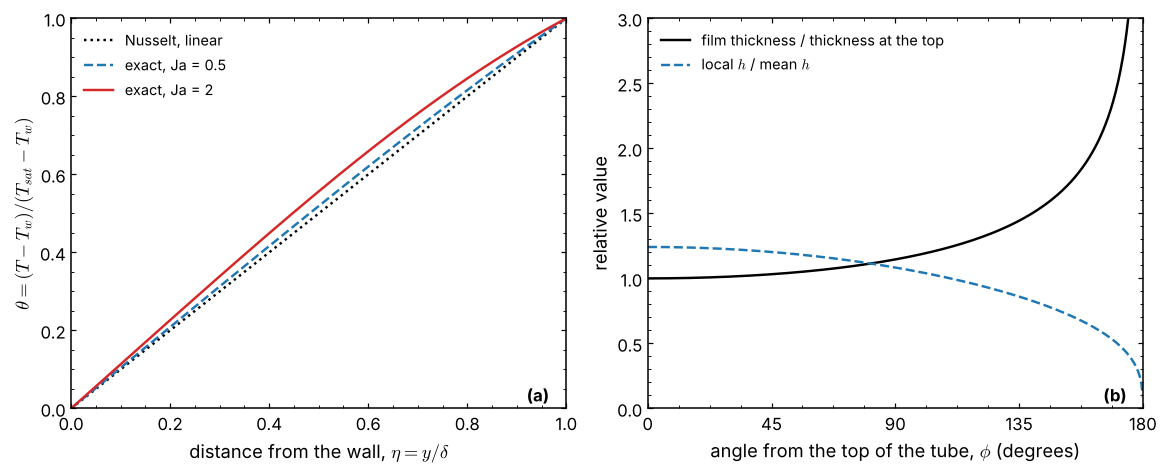

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.2))
eta = np.linspace(0, 1, 201)
ax1.plot(eta, eta, "k:", label="Nusselt, linear")
for Ja, style in ((0.5, "C0--"), (2.0, "C3-")):
    r = phase_change.film_condensation_subcooling(Ja)
    F = eta**3 / 6 - eta**4 / 24
    theta = np.concatenate(([0.0], np.cumsum(0.5 * (np.exp(-r["lam"] * F[1:]) + np.exp(-r["lam"] * F[:-1])) * np.diff(eta)))) * r["c"]
    ax1.plot(eta, theta, style, label=f"exact, Ja = {Ja:g}")
ax1.set_xlabel(r"distance from the wall, $\eta = y/\delta$")
ax1.set_ylabel(r"$\theta = (T - T_w)/(T_{sat} - T_w)$")
ax1.set_xlim(0, 1)
ax1.set_ylim(0, 1)
ax1.legend(loc="upper left")
panel_label(ax1, "(a)", x=0.92, y=0.06)

phi = np.linspace(1e-3, math.pi - 1e-3, 400)
S_phi = np.array([quad(lambda p: np.sin(p) ** (1 / 3), 0.0, ph)[0] for ph in phi])
delta_rel = S_phi**0.25 / np.sin(phi) ** (1 / 3) / (0.75 ** 0.25)
h_rel = (1 / delta_rel) / (np.trapezoid(1 / delta_rel, phi) / math.pi)
ax2.plot(np.degrees(phi), delta_rel, "k-", label=r"film thickness / thickness at the top")
ax2.plot(np.degrees(phi), h_rel, "C0--", label=r"local $h$ / mean $h$")
ax2.set_xlabel(r"angle from the top of the tube, $\phi$ (degrees)")
ax2.set_ylabel("relative value")
ax2.set_xlim(0, 180)
ax2.set_ylim(0, 3)
ax2.set_xticks([0, 45, 90, 135, 180])
ax2.legend(loc="upper left")
panel_label(ax2, "(b)", x=0.92, y=0.06)

**Figure 10.1.** (a) Temperature across the condensate film: Nusselt's linear profile and
the exact profiles of Eq. (10.4) for $\mathrm{Ja} = 0.5$ and 2, which are steeper at the wall
than at the interface: on its way to the wall, part of the latent heat warms the subcooled
liquid carried down from above. (b) Film thickness and local heat
transfer coefficient around a horizontal tube: the film thickens slowly over the upper
half and quickly near the bottom, where the condensate leaves.

## 10.4 Pool boiling

A wall heated a few kelvin above $T_{sat}$ in a pool of liquid at first loses heat by
natural convection. Above an *excess temperature* $\Delta T_e = T_w - T_{sat}$ of a few
kelvin, vapour bubbles form at cavities in the surface, grow, and leave: this is
*nucleate boiling*, in which the bubbles stir the liquid next to the wall and the heat
flux rises steeply with $\Delta T_e$. Rohsenow (1952) correlated it as

$$
q'' = \mu_l h_{fg}\left[\frac{g(\rho_l - \rho_v)}{\sigma}\right]^{1/2}
\left(\frac{c_{p,l}\,\Delta T_e}{C_{sf}\,h_{fg}\,\mathrm{Pr}_l^{\,n}}\right)^3 ,
\tag{10.7}
$$

where $\sigma$ is the surface tension. The surface enters through $C_{sf}$ (0.013, with
$n = 1$, for water on copper); the heat flux at a given $\Delta T_e$ is uncertain by a
factor of two between surfaces, though $\Delta T_e$ at a given flux, which goes as the cube
root, is uncertain by only about 25 %.

As the flux rises, the vapour leaving the surface in columns blocks the liquid coming
back to it. Zuber (1959) treated this as a hydrodynamic instability of the vapour columns
and found the *peak* or *critical heat flux*

$$
q''_{max} = C\,\rho_v h_{fg}\left[\frac{\sigma g(\rho_l - \rho_v)}{\rho_v^2}\right]^{1/4} ,
\tag{10.8}
$$

with $C = \pi/24 = 0.131$; Lienhard and Dhir (1973) showed that $C = 0.149$ fits large flat
heaters. Beyond the peak a vapour film blankets parts of the surface (transition
boiling), and above the *minimum heat flux*,

$$
q''_{min} = 0.09\,\rho_v h_{fg}\left[\frac{\sigma g(\rho_l - \rho_v)}{(\rho_l + \rho_v)^2}\right]^{1/4} ,
\tag{10.9}
$$

the surface is covered completely: *film boiling*. Heat then crosses the vapour film by
conduction and radiation. For a horizontal cylinder Bromley (1950) found a result of
Nusselt's form,

$$
\bar h_{conv} = 0.62\left[\frac{g\rho_v(\rho_l - \rho_v)\,h_{fg}'\,k_v^3}{\mu_v\,D\,\Delta T_e}\right]^{1/4} ,
\qquad h_{fg}' = h_{fg} + 0.4\,c_{p,v}\Delta T_e , \qquad
\bar h \approx \bar h_{conv} + \tfrac34 h_{rad} ,
\tag{10.10}
$$

with vapour properties at the film temperature and $h_{rad} = \varepsilon\sigma_{SB}(T_w^4 -
T_{sat}^4)/\Delta T_e$.

## 10.5 The immersion heater and the boiling crisis

Nukiyama (1934) measured the whole boiling curve with an electrically heated wire in
water. He controlled the power, not the temperature, and found that when the heat flux
passed its maximum, the wire jumped from nucleate boiling straight to film boiling at the
same flux, and glowed or melted. An electric heater behaves in the same way. Take an
immersion heater of 2 kW, a sheathed element 8 mm in diameter and 0.25 m long with an
emissivity of 0.8, in water boiling at 1 atm:

In [5]:
sat = properties.saturated_water(373.15)
q_max = phase_change.zuber_critical_heat_flux(sat["rho"], sat["rho_v"], sat["h_fg"], sat["sigma"])
q_max_zuber = phase_change.zuber_critical_heat_flux(sat["rho"], sat["rho_v"], sat["h_fg"], sat["sigma"], C=math.pi / 24)
q_min = phase_change.minimum_heat_flux(sat["rho"], sat["rho_v"], sat["h_fg"], sat["sigma"])
print(f"water at 1 atm: sigma = {1e3 * sat['sigma']:.2f} mN/m, h_fg = {sat['h_fg'] / 1e6:.4f} MJ/kg, rho_v = {sat['rho_v']:.4f} kg/m3")
print(f"q_max = {q_max / 1e6:.3f} MW/m2 (C = 0.149; Zuber's pi/24: {q_max_zuber / 1e6:.3f}); q_min = {q_min / 1e3:.1f} kW/m2")


def q_nucleate(dT):
    return phase_change.rohsenow_heat_flux(dT, sat["mu"], sat["h_fg"], sat["rho"], sat["rho_v"], sat["sigma"], sat["cp"], sat["Pr"])


D_el, L_el, P_el, eps_el = 0.008, 0.25, 2000.0, 0.8


def q_film(dT, D=D_el, eps=eps_el):
    vap = properties.steam_properties(min(max(373.15 + dT / 2, 380.0), 1300.0))
    h_conv = phase_change.bromley_film_boiling(D, dT, sat["rho"], vap["rho"], vap["k"], vap["mu"], vap["cp"], sat["h_fg"])
    h_rad = eps * SIGMA_SB * ((373.15 + dT) ** 4 - 373.15**4) / dT
    return (h_conv + 0.75 * h_rad) * dT


dT_peak = brentq(lambda d: q_nucleate(d) - q_max, 1.0, 100.0)
q_el = P_el / (math.pi * D_el * L_el)
dT_el = brentq(lambda d: q_nucleate(d) - q_el, 0.1, 100.0)
dT_min = brentq(lambda d: q_film(d) - q_min, 20.0, 2000.0)
dT_burn = brentq(lambda d: q_film(d) - q_max, 100.0, 5000.0)
print(f"nucleate boiling reaches q_max at an excess temperature of {dT_peak:.1f} K")
print(f"heater: {q_el / 1e3:.0f} kW/m2, {100 * q_el / q_max:.0f} % of q_max, surface {dT_el:.1f} K above saturation")
print(f"film boiling: q_min reached at dT = {dT_min:.0f} K; at q_max the surface would be {dT_burn:.0f} K above saturation"
      f" ({dT_burn + 100:.0f} C)")
print(f"power that would trip the heater into film boiling: {q_max * math.pi * D_el * L_el / 1e3:.1f} kW")

water at 1 atm: sigma = 58.91 mN/m, h_fg = 2.2564 MJ/kg, rho_v = 0.5982 kg/m3
q_max = 1.261 MW/m2 (C = 0.149; Zuber's pi/24: 1.108); q_min = 19.0 kW/m2
nucleate boiling reaches q_max at an excess temperature of 20.8 K
heater: 318 kW/m2, 25 % of q_max, surface 13.2 K above saturation
film boiling: q_min reached at dT = 70 K; at q_max the surface would be 1840 K above saturation (1940 C)
power that would trip the heater into film boiling: 7.9 kW


The heater runs at 320 kW/m², a quarter of the critical heat flux of 1.26 MW/m², with its
surface 13 K above the boiling point. Nucleate boiling reaches the peak at an excess
temperature of 21 K, within the 20–40 K that Nukiyama measured, and the peak itself lies
in his range of 1.3–2.1 MW/m². Raising the power fourfold, to 7.9 kW, would carry the
element past the peak; then the only steady state at that flux is on the film-boiling
branch, with the surface some 1840 K above the water, at about 1940 °C: above the
melting point of the steel sheath. This is the *boiling crisis*, and in a nuclear reactor
or a boiler tube with a fixed heat input it is a failure, not a change of regime. Once in
film boiling, the heater would stay there until the flux fell below the minimum, 19
kW/m²: the boiling curve has a hysteresis loop.

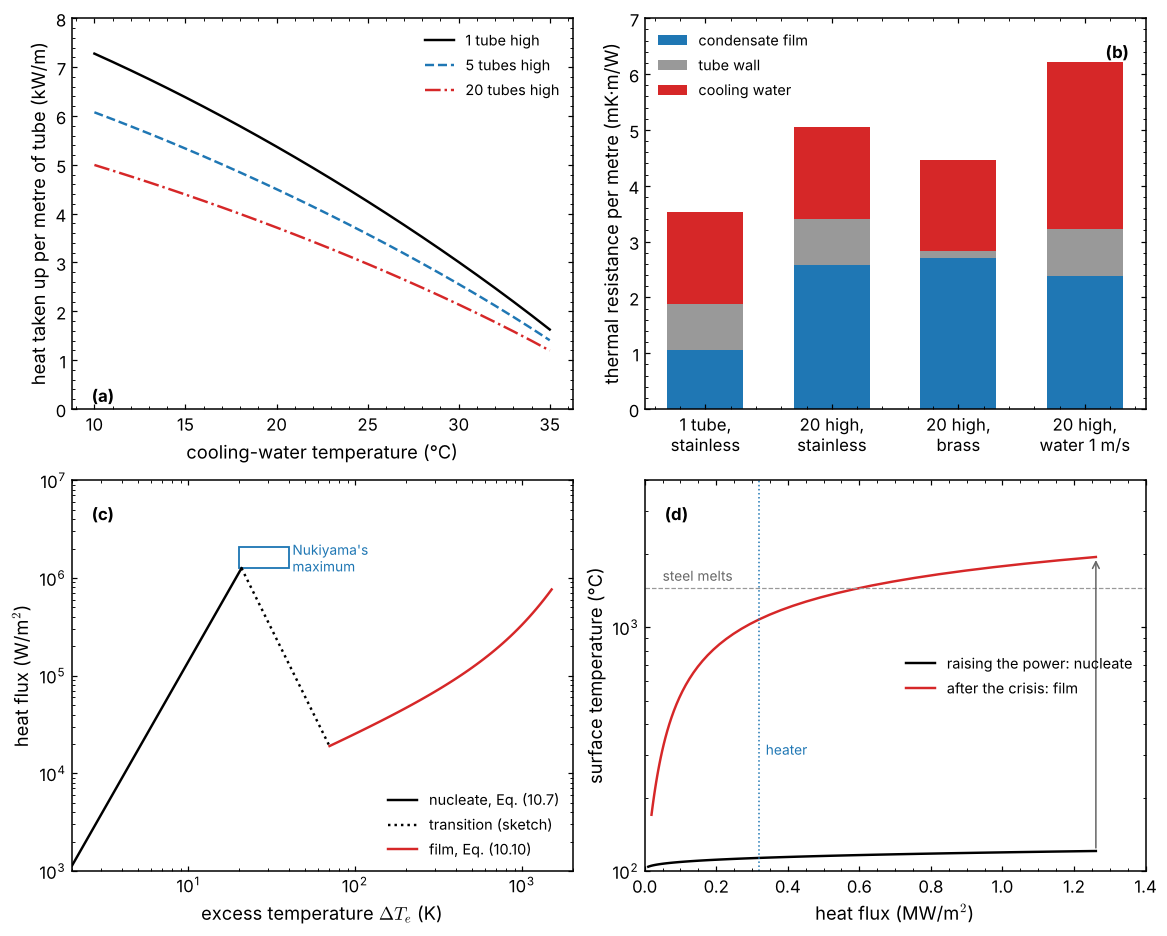

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.4))
(ax1, ax2), (ax3, ax4) = axes

T_cws = np.linspace(10.0, 35.0, 26)
for N, style in ((1, "k-"), (5, "C0--"), (20, "C3-.")):
    ax1.plot(T_cws, [condenser_tube(273.15 + T, N=N)["q"] / 1e3 for T in T_cws], style, label=f"{N} tube{'s' if N > 1 else ''} high")
ax1.set_xlabel("cooling-water temperature (°C)")
ax1.set_ylabel("heat taken up per metre of tube (kW/m)")
ax1.set_ylim(0, 8)
ax1.legend(loc="upper right")
panel_label(ax1, "(a)", x=0.04, y=0.06)

cases = [("1 tube,\nstainless", condenser_tube(298.15, N=1)), ("20 high,\nstainless", condenser_tube(298.15, N=20)),
         ("20 high,\nbrass", condenser_tube(298.15, N=20, k_wall=110.0)), ("20 high,\nwater 1 m/s", condenser_tube(298.15, N=20, U=1.0))]
x = np.arange(len(cases))
bottom = np.zeros(len(cases))
for key, color, label in (("R_o", "C0", "condensate film"), ("R_wall", "0.6", "tube wall"), ("R_i", "C3", "cooling water")):
    vals = np.array([1e3 * c[key] for _, c in cases])
    ax2.bar(x, vals, 0.6, bottom=bottom, color=color, label=label)
    bottom += vals
ax2.set_xticks(x)
ax2.set_xticklabels([name for name, _ in cases])
ax2.set_ylabel("thermal resistance per metre (mK·m/W)")
ax2.set_ylim(0, 7)
ax2.legend(loc="upper left")
panel_label(ax2, "(b)", x=0.92, y=0.94)

dT_nb = np.geomspace(2.0, dT_peak, 60)
dT_fb = np.geomspace(dT_min, 1500.0, 60)
ax3.loglog(dT_nb, q_nucleate(dT_nb), "k-", label="nucleate, Eq. (10.7)")
ax3.loglog([dT_peak, dT_min], [q_max, q_min], "k:", label="transition (sketch)")
ax3.loglog(dT_fb, [q_film(d) for d in dT_fb], "C3-", label="film, Eq. (10.10)")
ax3.add_patch(plt.Rectangle((20, 1.256e6), 20, 2.093e6 - 1.256e6, fill=False, ec="C0", lw=1.2))
ax3.text(42, 1.6e6, "Nukiyama's\nmaximum", color="C0", va="center", fontsize=9)
ax3.set_xlabel(r"excess temperature $\Delta T_e$ (K)")
ax3.set_ylabel(r"heat flux (W/m$^2$)")
ax3.set_xlim(2, 2000)
ax3.set_ylim(1e3, 1e7)
ax3.legend(loc="lower right")
panel_label(ax3, "(c)", x=0.04, y=0.94)

q_up = np.geomspace(1e4, q_max, 50)
dT_up = [brentq(lambda d: q_nucleate(d) - q, 0.01, 100.0) for q in q_up]
q_down = np.geomspace(q_min, q_max, 50)
dT_down = [brentq(lambda d: q_film(d) - q, 1.0, 5000.0) for q in q_down]
ax4.semilogy(q_up / 1e6, np.array(dT_up) + 100, "k-", label="raising the power: nucleate")
ax4.semilogy(q_down / 1e6, np.array(dT_down) + 100, "C3-", label="after the crisis: film")
ax4.annotate("", xy=(q_max / 1e6, dT_burn + 100), xytext=(q_max / 1e6, dT_peak + 100),
             arrowprops=dict(arrowstyle="->", color="0.4"))
ax4.axhline(1450, color="0.6", ls="--", lw=0.8)
ax4.text(0.05, 1550, "steel melts", color="0.4", fontsize=9)
ax4.axvline(q_el / 1e6, color="C0", ls=":", lw=1.0)
ax4.text(q_el / 1e6 + 0.02, 300, "heater", color="C0", fontsize=9)
ax4.set_xlabel(r"heat flux (MW/m$^2$)")
ax4.set_ylabel("surface temperature (°C)")
ax4.set_xlim(0, 1.4)
ax4.set_ylim(100, 4000)
ax4.legend(loc="center right")
panel_label(ax4, "(d)", x=0.04, y=0.94)
plt.show()

**Figure 10.2.** (a) Heat taken up per metre of condenser tube against the cooling-water
temperature, for a single tube and for banks 5 and 20 tubes high (steam at 40 °C,
stainless tubes, water at 2 m/s). (b) The three resistances per metre with water at
25 °C, for a single tube and a bank 20 high, with brass tubes, and with the water slowed
to 1 m/s. (c) The boiling curve of water at 1 atm on the 8 mm heater: Rohsenow's nucleate
boiling up to the critical heat flux, a sketch of transition boiling, and Bromley's film
boiling with radiation; the box is the range of maxima measured by Nukiyama. (d) Surface
temperature of the heater when its power is raised: at the critical heat flux it jumps
to the film-boiling branch, above the melting point of steel.

## 10.6 Checks

**The subcooled film.** Equations (10.4) are solved three ways. The package uses
Gauss–Legendre quadrature for $c(\lambda)$ and bisection for $\lambda$.
`reference.film_condensation_bvp` solves the boundary-value problem by collocation, with
$\lambda$ as an unknown parameter. And `reference.film_condensation_march` assumes no
similarity at all: with $s = \ln x$ and the scaled fourth power of the film thickness
$d = \delta^4 g\rho_l(\rho_l - \rho_v)h_{fg}/(4\mu_l k_l\Delta T x)$, which is 1 for
Nusselt's film, the energy equation of the film and the interface balance become

$$
\theta'' + 3\,\mathrm{Ja}\,\theta'(1)\,f\,\theta' = 4\,\mathrm{Ja}\,d\,f'\,\frac{\partial\theta}{\partial s} ,
\qquad \frac{dd}{ds} + d = \theta'(1) ,
\tag{10.11}
$$

which are marched down the plate from Nusselt's linear profile, with implicit steps in $s$
and finite differences across the film. The local $h_{fg}'/h_{fg} = \theta'(0)^4/d$ must
settle on the value of Eq. (10.5).

In [7]:
Jas = np.geomspace(1e-3, 3.0, 25)
ratio_q = np.array([phase_change.film_condensation_subcooling(Ja)["ratio"] for Ja in Jas])
Jas_c = np.array([0.01, 0.1, 0.3, 1.0, 3.0])
ratio_c = np.array([reference.film_condensation_bvp(Ja)["ratio"] for Ja in Jas_c])
ratio_q_c = np.array([phase_change.film_condensation_subcooling(Ja)["ratio"] for Ja in Jas_c])
print(f"quadrature against collocation: largest difference {np.max(np.abs(ratio_q_c - ratio_c)):.1e}")
small = phase_change.film_condensation_subcooling(1e-5)["ratio"]
print(f"(h_fg'/h_fg - 1)/Ja at Ja = 1e-5: {(small - 1) / 1e-5:.5f}  (27/40 = {27 / 40:.5f})")
dev_r = (1 + 0.68 * Jas) / ratio_q - 1
print(f"Rohsenow's 1 + 0.68 Ja against the exact ratio: {100 * np.max(np.abs(dev_r[Jas <= 1])):.2f} % up to Ja = 1,"
      f" {100 * dev_r[-1]:+.1f} % at Ja = 3")

marches = {Ja: reference.film_condensation_march(Ja) for Ja in (0.1, 0.5, 2.0)}
for Ja, m in marches.items():
    exact = phase_change.film_condensation_subcooling(Ja)["ratio"]
    print(f"march, Ja = {Ja}: h_fg'/h_fg at x/x0 = e^15: {m['ratio'][-1]:.6f} (exact {exact:.6f}, {m['ratio'][-1] / exact - 1:+.1e})")
n_etas = [25, 50, 100, 200, 400]
exact05 = phase_change.film_condensation_subcooling(0.5)["ratio"]
err_m = np.array([abs(reference.film_condensation_march(0.5, n_eta=n)["ratio"][-1] - exact05) for n in n_etas])
print("march errors, Ja = 0.5:", " ".join(f"{e:.1e}" for e in err_m), "; orders:", np.round(np.log2(err_m[:-1] / err_m[1:]), 2))
nodes = [4, 6, 8, 12, 16, 24]
exact3 = reference.film_condensation_bvp(3.0)["ratio"]
err_gl = np.array([abs(phase_change.film_condensation_subcooling(3.0, n_nodes=n)["ratio"] - exact3) for n in nodes])
print("Gauss-Legendre nodes", nodes, "errors at Ja = 3:", " ".join(f"{e:.0e}" for e in err_gl))

quadrature against collocation: largest difference 1.9e-13
(h_fg'/h_fg - 1)/Ja at Ja = 1e-5: 0.67500  (27/40 = 0.67500)
Rohsenow's 1 + 0.68 Ja against the exact ratio: 0.64 % up to Ja = 1, -4.7 % at Ja = 3
march, Ja = 0.1: h_fg'/h_fg at x/x0 = e^15: 1.067733 (exact 1.067741, -7.5e-06)
march, Ja = 0.5: h_fg'/h_fg at x/x0 = e^15: 1.343222 (exact 1.343256, -2.5e-05)
march, Ja = 2.0: h_fg'/h_fg at x/x0 = e^15: 2.429018 (exact 2.429099, -3.3e-05)


march errors, Ja = 0.5: 4.6e-04 1.3e-04 3.4e-05 8.6e-06 2.2e-06 ; orders: [1.85 1.93 1.96 1.94]
Gauss-Legendre nodes [4, 6, 8, 12, 16, 24] errors at Ja = 3: 5e-05 2e-08 2e-12 1e-13 1e-13 1e-13


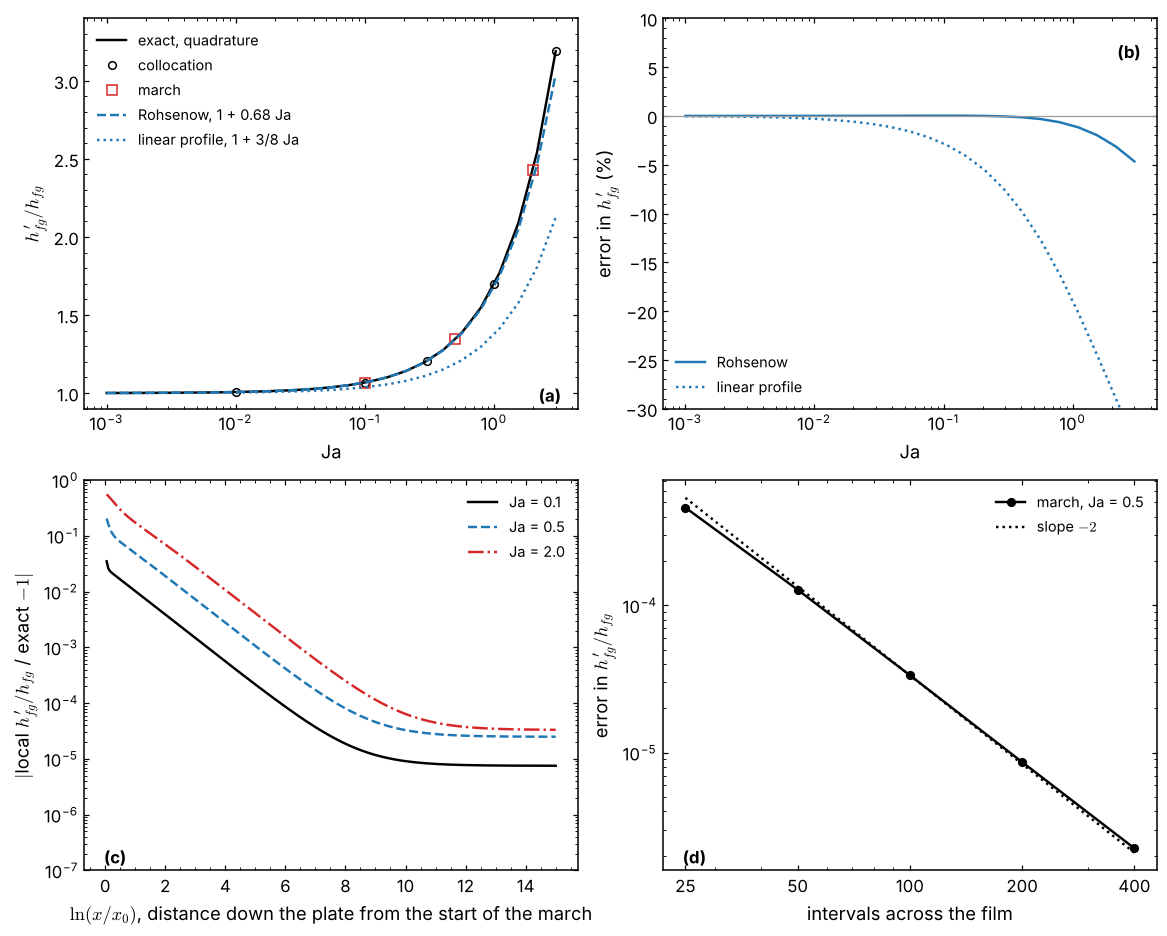

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.4))
(ax1, ax2), (ax3, ax4) = axes

ax1.semilogx(Jas, ratio_q, "k-", label="exact, quadrature")
ax1.semilogx(Jas_c, ratio_c, "ko", ms=5, mfc="none", label="collocation")
ax1.semilogx(list(marches), [m["ratio"][-1] for m in marches.values()], "C3s", ms=6, mfc="none", label="march")
ax1.semilogx(Jas, 1 + 0.68 * Jas, "C0--", label="Rohsenow, 1 + 0.68 Ja")
ax1.semilogx(Jas, 1 + 0.375 * Jas, "C0:", label="linear profile, 1 + 3/8 Ja")
ax1.set_xlabel("Ja")
ax1.set_ylabel(r"$h_{fg}'/h_{fg}$")
ax1.set_ylim(0.9, 3.4)
ax1.legend(loc="upper left")
panel_label(ax1, "(a)", x=0.92, y=0.06)

ax2.semilogx(Jas, 100 * dev_r, "C0-", label="Rohsenow")
ax2.semilogx(Jas, 100 * ((1 + 0.375 * Jas) / ratio_q - 1), "C0:", label="linear profile")
ax2.axhline(0.0, color="0.6", lw=0.8)
ax2.set_xlabel("Ja")
ax2.set_ylabel(r"error in $h_{fg}'$ (%)")
ax2.set_ylim(-30, 10)
ax2.legend(loc="lower left")
panel_label(ax2, "(b)", x=0.92, y=0.94)

for (Ja, m), style in zip(marches.items(), ("k-", "C0--", "C3-.")):
    exact = phase_change.film_condensation_subcooling(Ja)["ratio"]
    ax3.semilogy(m["s"], np.abs(m["ratio"] / exact - 1), style, label=f"Ja = {Ja}")
ax3.set_xlabel(r"$\ln(x/x_0)$, distance down the plate from the start of the march")
ax3.set_ylabel(r"$|$local $h_{fg}'/h_{fg}$ / exact $- 1|$")
ax3.set_ylim(1e-7, 1)
ax3.legend(loc="upper right")
panel_label(ax3, "(c)", x=0.04, y=0.06)

ax4.loglog(n_etas, err_m, "ko-", ms=5, label="march, Ja = 0.5")
ax4.loglog(n_etas, err_m[2] * (np.array(n_etas) / n_etas[2]) ** -2.0, "k:", label="slope $-2$")
ax4.set_xticks(n_etas)
ax4.xaxis.set_major_formatter(plt.ScalarFormatter())
ax4.xaxis.set_minor_formatter(plt.NullFormatter())
ax4.set_xlabel("intervals across the film")
ax4.set_ylabel(r"error in $h_{fg}'/h_{fg}$")
ax4.legend(loc="upper right")
panel_label(ax4, "(d)", x=0.04, y=0.06)
plt.show()

**Figure 10.3.** Checks of the subcooled-film analysis. (a) $h_{fg}'/h_{fg}$ against the
Jakob number, from the quadrature, collocation and the march, with Rohsenow's form and the
linear-profile correction. (b) Errors of the two approximate forms. (c) The march starts
from Nusselt's linear profile and settles on the exact solution as the film moves down the
plate. (d) Error of the march against the number of intervals across the film.

Quadrature and collocation agree to $2 \times 10^{-13}$; the 40-point Gauss–Legendre rule is
converged (12 points already give $10^{-13}$ at $\mathrm{Ja} = 3$), and the coefficient of
the small-Ja expansion is 0.67500. The march forgets Nusselt's starting profile within a
factor of about $e^{10}$ in distance (sooner for small Ja) and then agrees with the exact
ratio to a few times $10^{-5}$ with 100 intervals, with errors falling at second order. Rohsenow's form is within 1 % of the exact
ratio up to $\mathrm{Ja} = 1$ and 5 % low at $\mathrm{Ja} = 3$; the linear-profile
correction, which counts the enthalpy of the film but not the curvature of its
temperature profile, is a third low at $\mathrm{Ja} = 3$.

## 10.7 What to trust

* *Film condensation* theory is good to about 10–20 % for laminar, smooth films of pure
  vapour; waves raise $h$, and vapour shear in a condenser can raise or lower it.
* *Non-condensable gases* are the main danger in real condensers: a few per cent of air
  collects at the interface and can halve the coefficient, because the steam must diffuse
  through it (Chapter 16, Exercise 3, computes an example). Condensers have air extraction
  for this reason.
* *Nucleate boiling* correlations are uncertain by a factor of two in heat flux, because
  the surface (its cavities, wetting and fouling) matters and is not in the formula.
* *The critical heat flux* from Eq. (10.8) is good to about 15–20 % for large horizontal
  heaters in saturated liquid; small cylinders, subcooling and flow change it, and a
  safety margin of two or more is common.
* *Film boiling* correlations are good to about 20 %, but the wall temperature they
  predict is what matters, and it is sensitive to the emissivity.

## Summary

* Nusselt's laminar film theory gives the film thickness (10.2) and the mean coefficient
  (10.3) on a vertical plate, and (10.6) on a horizontal tube, with the constant 0.728.
* The subcooling of the film is included exactly by Eqs. (10.4)–(10.5):
  $h_{fg}' = h_{fg}(1 + \tfrac{27}{40}\mathrm{Ja} + \dots)$, close to Rohsenow's 0.68.
* A steam condenser's resistance is shared between the condensate film, the tube wall and
  the cooling water; the film's share grows with the depth of the tube bank.
* Nucleate boiling follows Rohsenow's correlation (10.7) up to the critical heat flux
  (10.8), 1.26 MW/m² for water at 1 atm; film boiling (10.9)–(10.10) takes over beyond it.
* A heater with a fixed power that passes the critical heat flux jumps to film boiling and
  can melt: the boiling crisis.

## Exercises

Sample solutions are in [`solutions/part2_convection/10_solutions.ipynb`](../../solutions/part2_convection/10_solutions.ipynb).

1. **Vertical or horizontal?** Steam at 1 atm condenses on a tube 25 mm in diameter and
   2 m long whose wall is at 90 °C. Compare the condensation rate with the tube vertical
   and horizontal. Check the film Reynolds number $4\Gamma/\mu_l$ at the bottom of the
   vertical tube.
2. **Pressure and the critical heat flux.** Find the critical heat flux of water at
   saturation temperatures of 100, 150 and 200 °C with `properties.saturated_water`.
   Which properties make it rise with pressure?
3. **Quenching again.** Chapter 5 (Exercise 4) took $h = 1000$ W/(m² K) for a steel bar in
   water while its surface was above 600 °C. Estimate the film-boiling coefficient of a
   bar 50 mm in diameter at 700 °C in saturated water at 1 atm (emissivity 0.8), and the
   minimum heat flux. Why is the estimate of Chapter 5 larger?
4. **Limescale in a kettle.** Astana's tap water is hard. A layer of limescale 0.5 mm
   thick ($k \approx 1$ W/(m K)) forms on the heater of Section 10.5. By how much does it
   raise the temperature of the metal sheath at 2 kW? How thick may the scale become
   before the sheath reaches 400 °C?

## Suggested references

* W. Nusselt, "Die Oberflächenkondensation des Wasserdampfes", *Z. Ver. Dtsch. Ing.*
  **60**, 541 and 569 (1916).
* W. M. Rohsenow, "Heat transfer and temperature distribution in laminar film
  condensation", *Trans. ASME* **78**, 1645 (1956).
* W. M. Rohsenow, "A method of correlating heat-transfer data for surface boiling of
  liquids", *Trans. ASME* **74**, 969 (1952).
* S. Nukiyama, "The maximum and minimum values of the heat Q transmitted from metal to
  boiling water under atmospheric pressure", *J. Soc. Mech. Eng. Japan* **37**, 367 (1934);
  English translation in *Int. J. Heat Mass Transfer* **27**, 959 (1984).
* N. Zuber, *Hydrodynamic Aspects of Boiling Heat Transfer*, PhD thesis, University of
  California, Los Angeles, report AECU-4439 (1959).
* J. H. Lienhard and V. K. Dhir, "Hydrodynamic prediction of peak pool-boiling heat fluxes
  from finite bodies", *J. Heat Transfer* **95**, 152 (1973).
* P. J. Berenson, "Film-boiling heat transfer from a horizontal surface", *J. Heat
  Transfer* **83**, 351 (1961).
* L. A. Bromley, "Heat transfer in stable film boiling", *Chem. Eng. Prog.* **46**, 221
  (1950).
* IAPWS, *Revised Release on the Surface Tension of Ordinary Water Substance*, R1-76(2014).

---

**Previous:** [9. Natural convection](09_natural_convection.ipynb) &nbsp;·&nbsp; **Next:** [11. Heat exchangers](11_heat_exchangers.ipynb)